In [ ]:
# Análisis de clorofila

In [4]:
import os                          # Operar con archivos y directorios
import numpy as np                 # Operaciones numéricas y manejo de arrays
import pandas as pd                # Manejo de tablas y CSVs
import xarray as xr                # Lectura y manejo de archivos netCDF
from scipy.spatial import cKDTree  # Join espacial más cercano (nearest neighbor)
import matplotlib.pyplot as plt    # Gráficos y mapas!
import cartopy.crs as ccrs         # Proyecciones cartográficas
import cartopy.feature as cfeature # Costas, océanos, continentes, etc
import geopandas as gpd
import rioxarray as xr


In [7]:
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt
import pandas as pd

In [8]:
import os

# Mostrar directorio de trabajo actual
print(os.getcwd())

# Mostrar archivos de la carpeta actual
print(os.listdir())

/home/jovyan/Tareas/ohwe26-proy2-python/notebooks
['.ipynb_checkpoints', '01_exploracion_area_estudio.ipynb', 'Prueba-2-GFW.ipynb', 'CHL_mensual_Shiretoko_2021_2025.nc', 'Shiretoko_EBSA_10401_10402.geojson', 'Clorofila_Pesca.ipynb', 'GFW_Shiretoko_2020_2024.csv']


In [9]:
# Exploración del archivo netCDF generado por Víctor para los datos de clorofila mensual para la región de interés de 2021-2025
# Los datos corresponden a un área más extensa, así que posteriormente se deberán recortar al polígono del AMP. 
nc_file = "CHL_mensual_Shiretoko_2021_2025.nc"

ds = xr.open_dataset(nc_file)
ds # a ver el dataset que tenemos?


<xarray.Dataset> Size: 3MB
Dimensions:    (time: 60, latitude: 96, longitude: 120)
Coordinates:
  * time       (time) datetime64[ns] 480B 2021-01-01 2021-02-01 ... 2025-12-01
  * latitude   (latitude) float32 384B 42.02 42.06 42.1 ... 45.9 45.94 45.98
  * longitude  (longitude) float32 480B 143.0 143.1 143.1 ... 147.9 147.9 148.0
Data variables:
    CHL        (time, latitude, longitude) float32 3MB ...
Attributes: (12/92)
    Conventions:                     CF-1.8, ACDD-1.3
    DPM_reference:                   GC-UD-ACRI-PUG
    IODD_reference:                  GC-UD-ACRI-PUG
    acknowledgement:                 The Licensees will ensure that original ...
    citation:                        The Licensees will ensure that original ...
    cmems_product_id:                OCEANCOLOUR_GLO_BGC_L4_MY_009_104
    ...                              ...
    time_coverage_resolution:        P28D
    time_coverage_start:             2026-01-31T18:24:51Z
    title:                           cmems_obs-oc_glo_bgc-plankton_my_l4-mult...
    westernmost_longitude:           -180.0
    westernmost_valid_longitude:     -180.0
    copernicusmarine_version:        2.5.1

In [10]:
# Tomamos el nombre de la variable
var_name = list(ds.data_vars)[0]  # devolveme la primera variable, asi no tenemos que escribirla y equivocarnos
print("Variable seleccionada:", var_name)

Variable seleccionada: CHL


In [11]:
#carga del archivo GEOJSON para recortar los datos de clorofila al polígono de Shiretoko
geojson_file = "Shiretoko_EBSA_10401_10402.geojson"

In [12]:
#Lectura del polígono
poligono = gpd.read_file(geojson_file)

In [13]:
#Visualización de la información del polígono
print(poligono.head())

   AreaNumber                             AreaName  \
0     10401.0  Shiretoko (Shari, Utoro) side coast   
1     10402.0         Shiretoko (Rausu) side coast   

                             Municipali       Area  \
0     Shari, Rausu, Hokkaido Prefecture  215.07212   
1  Shibetsu, Rausu, Hokkaido Prefecture  323.24391   

                                                 URL  \
0  http://www.env.go.jp/en/nature/biodic/kaiyo-ho...   
1  http://www.env.go.jp/en/nature/biodic/kaiyo-ho...   

                                            geometry  
0  MULTIPOLYGON (((145.33396 44.34602, 145.3339 4...  
1  MULTIPOLYGON (((145.38782 44.34131, 145.38698 ...  


In [14]:
#Confirmar que el archivo de clorofila y el polígnono están en el mismo sistema de coordenadas
print("CRS:", poligono.crs)
print("Geometrías:", poligono.geometry.geom_type)
print("Extensión:", poligono.total_bounds)

CRS: EPSG:4326
Geometrías: 0    MultiPolygon
1    MultiPolygon
dtype: str
Extensión: [144.78856639  43.78250393 145.48289701  44.48055712]


In [15]:
#Coincide el sistema de coordenadas, se visualiza la extensión del polígono de GEOJSON y de los datos de clorofila
# Seleccionar clorofila del primer mes
chl_enero = ds["CHL"].isel(time=0)

# Revisar la fecha
print(ds.time.values[0])


2021-01-01T00:00:00.000000000


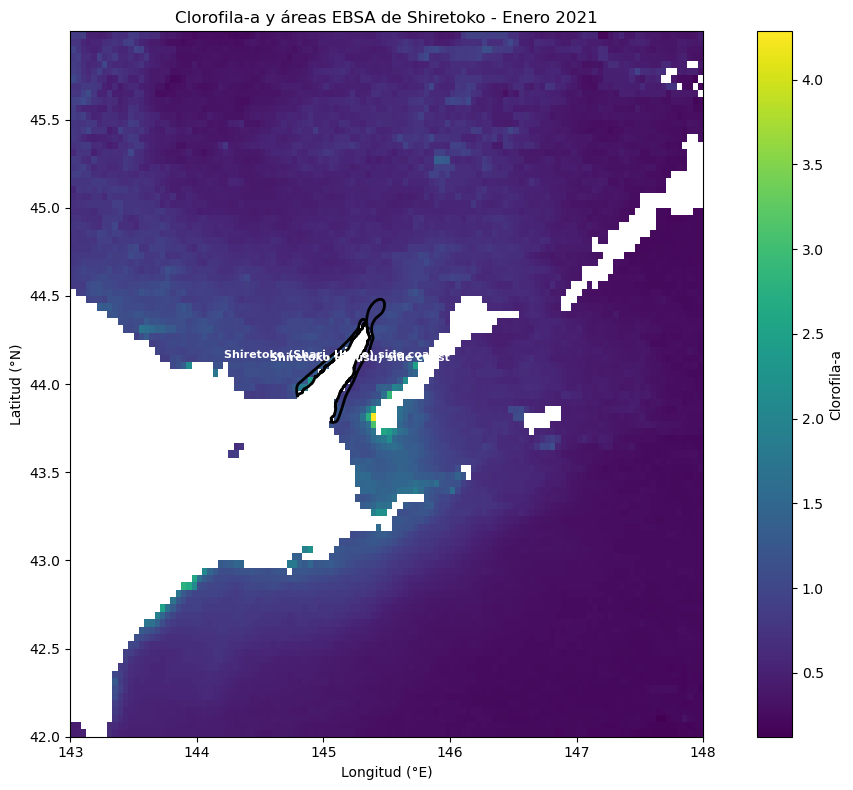

In [16]:
#Visualizar clorfoila y ambos polígonos 

# Crear figura
fig, ax = plt.subplots(figsize=(11, 8))

# 1. Mostrar raster de clorofila
chl_enero.plot(
    ax=ax,
    x="longitude",
    y="latitude",
    cmap="viridis",
    cbar_kwargs={"label": "Clorofila-a"}
)

# 2. Superponer los polígonos EBSA
poligono.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2,
    label="Límites EBSA"
)

# 3. Agregar nombres de las áreas
for _, row in poligono.iterrows():
    centro = row.geometry.representative_point()

    ax.annotate(
        row["AreaName"],
        (centro.x, centro.y),
        fontsize=8,
        color="white",
        weight="bold",
        ha="center"
    )

# 4. Configurar mapa
ax.set_title("Clorofila-a y áreas EBSA de Shiretoko - Enero 2021")
ax.set_xlabel("Longitud (°E)")
ax.set_ylabel("Latitud (°N)")

plt.tight_layout()
plt.show()

In [17]:
#Preparar los datos de clorofila, genera un DataArray de clorofila identificado como raster, con dimensiones espaciales y CRS definidos

da = ds["CHL"]

da = da.rio.set_spatial_dims(
    x_dim="longitude",
    y_dim="latitude"
)

da = da.rio.write_crs("EPSG:4326")

In [18]:
print(da.dims)
print(da.rio.crs)
print(da.shape)

('time', 'latitude', 'longitude')
EPSG:4326
(60, 96, 120)


In [19]:
#Recorte de los datos
chl_clip = da.rio.clip(
    poligono.geometry,
    poligono.crs,
    drop=True
)

In [20]:
print("Datos originales:")
print(da.shape)

print("Datos recortados:")
print(chl_clip.shape)

Datos originales:
(60, 96, 120)
Datos recortados:
(60, 17, 17)


In [21]:
# Contar píxeles válidos del primer mes
pixeles_validos = chl_clip.isel(time=0).count().values

# Contar el total de posiciones espaciales
pixeles_totales = (
    chl_clip.sizes["latitude"] *
    chl_clip.sizes["longitude"]
)

print("Píxeles totales:", pixeles_totales)
print("Píxeles válidos:", pixeles_validos)
print("Píxeles enmascarados:", pixeles_totales - pixeles_validos)

Píxeles totales: 289
Píxeles válidos: 33
Píxeles enmascarados: 256


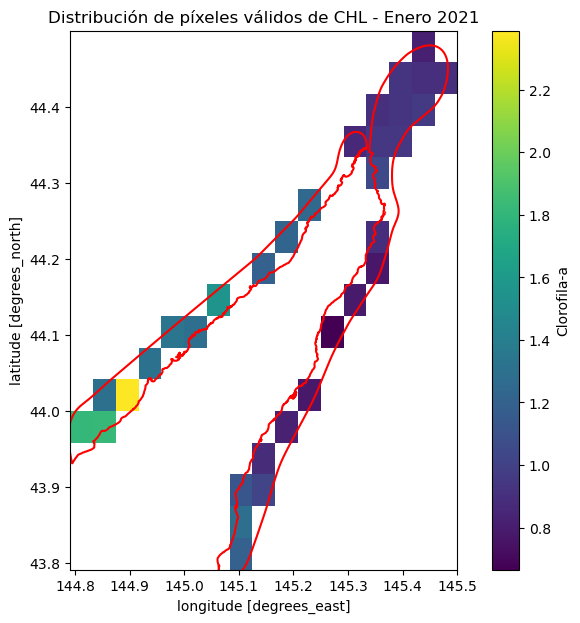

In [22]:
#Distribución de pixeles válidos

fig, ax = plt.subplots(figsize=(9, 7))

chl_clip.isel(time=0).plot(
    ax=ax,
    cmap="viridis",
    cbar_kwargs={"label": "Clorofila-a"}
)

poligono.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5
)

ax.set_title("Distribución de píxeles válidos de CHL - Enero 2021")
plt.show()

In [23]:
# Contar píxeles válidos para cada uno de los 60 meses
pixeles_por_mes = chl_clip.count(
    dim=["latitude", "longitude"]
)

# Convertir a DataFrame
pixeles_df = pixeles_por_mes.to_dataframe(
    name="pixeles_validos"
).reset_index()

print(pixeles_df.head(20))

         time  spatial_ref  pixeles_validos
0  2021-01-01            0               33
1  2021-02-01            0               33
2  2021-03-01            0               33
3  2021-04-01            0               33
4  2021-05-01            0               33
5  2021-06-01            0               33
6  2021-07-01            0               33
7  2021-08-01            0               33
8  2021-09-01            0               33
9  2021-10-01            0               33
10 2021-11-01            0               33
11 2021-12-01            0               33
12 2022-01-01            0               33
13 2022-02-01            0               33
14 2022-03-01            0               33
15 2022-04-01            0               33
16 2022-05-01            0               33
17 2022-06-01            0               33
18 2022-07-01            0               33
19 2022-08-01            0               33


In [24]:
# Identificar valores únicos de píxeles válidos
print(pixeles_df["pixeles_validos"].value_counts().sort_index())

pixeles_validos
31     1
33    59
Name: count, dtype: int64


In [25]:
# Identificar meses con menos de 33 píxeles válidos en todo el set de datos

meses_incompletos = pixeles_df[
    pixeles_df["pixeles_validos"] < 33
]

print(meses_incompletos)

         time  spatial_ref  pixeles_validos
37 2024-02-01            0               31


In [26]:
#Como hay muchos vacíos de información, se procede a adoptar un área más amplia.
# Recorte espacial de clorofila mediante coordenadas

chl_rect = da.sel(
    longitude=slice(144.5, 145.8),
    latitude=slice(43.7, 44.8)
)

In [27]:
# Comprobar dimensiones
print("Dimensiones originales:", da.shape)
print("Dimensiones recortadas:", chl_rect.shape)

print("Longitud:", float(chl_rect.longitude.min().values),
      float(chl_rect.longitude.max().values))

print("Latitud:", float(chl_rect.latitude.min().values),
      float(chl_rect.latitude.max().values))

Dimensiones originales: (60, 96, 120)
Dimensiones recortadas: (60, 26, 31)
Longitud: 144.52084350585938 145.77084350585938
Latitud: 43.729164123535156 44.77083206176758


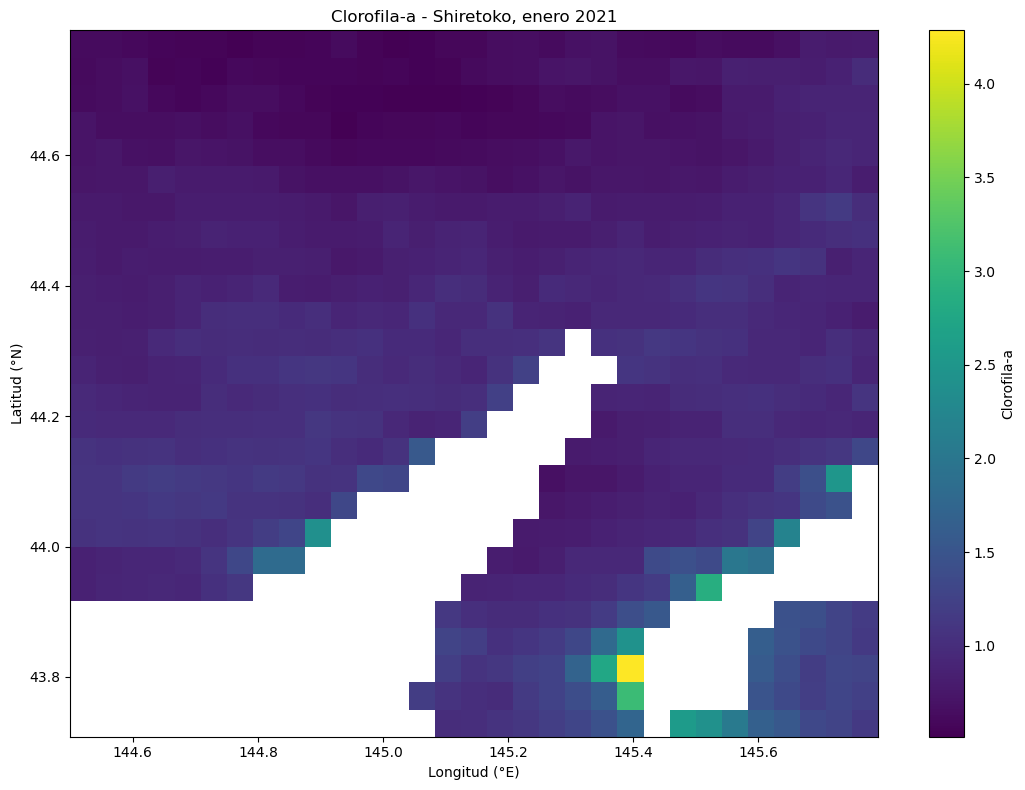

In [28]:
#Visualización con datos de un mes
fig, ax = plt.subplots(figsize=(11, 8))

chl_rect.isel(time=0).plot(
    ax=ax,
    cmap="viridis",
    cbar_kwargs={"label": "Clorofila-a"}
)

ax.set_title("Clorofila-a - Shiretoko, enero 2021")
ax.set_xlabel("Longitud (°E)")
ax.set_ylabel("Latitud (°N)")

plt.tight_layout()
plt.show()


In [29]:
#Comprobación de disponibilidad en los 60 meses 
pixeles_rect = chl_rect.count(
    dim=["latitude", "longitude"]
)

pixeles_rect_df = pixeles_rect.to_dataframe(
    name="pixeles_validos"
).reset_index()

print(pixeles_rect_df)

         time  spatial_ref  pixeles_validos
0  2021-01-01            0              655
1  2021-02-01            0              655
2  2021-03-01            0              655
3  2021-04-01            0              655
4  2021-05-01            0              655
5  2021-06-01            0              655
6  2021-07-01            0              655
7  2021-08-01            0              655
8  2021-09-01            0              655
9  2021-10-01            0              655
10 2021-11-01            0              655
11 2021-12-01            0              655
12 2022-01-01            0              655
13 2022-02-01            0              625
14 2022-03-01            0              655
15 2022-04-01            0              655
16 2022-05-01            0              655
17 2022-06-01            0              655
18 2022-07-01            0              655
19 2022-08-01            0              655
20 2022-09-01            0              655
21 2022-10-01            0      

In [30]:
# Copernicus ya proporciona composiciones mensuales de clorofila, ahora se calculará el promedio espacial de los pixeles del nuevo rectángulo para cada mes

# Convertir NetCDF recortado a DataFrame

chl_df = chl_rect.to_dataframe(
    name="CHL"
).reset_index()

# Convertir fecha a formato datetime
chl_df["time"] = pd.to_datetime(chl_df["time"])

# Crear columnas de año y mes
chl_df["year"] = chl_df["time"].dt.year
chl_df["month"] = chl_df["time"].dt.month

# Revisar información
print(chl_df.head())
print("Total de registros:", len(chl_df))

        time   latitude   longitude  spatial_ref  CHL  year  month
0 2021-01-01  43.729164  144.520844            0  NaN  2021      1
1 2021-01-01  43.729164  144.562515            0  NaN  2021      1
2 2021-01-01  43.729164  144.604172            0  NaN  2021      1
3 2021-01-01  43.729164  144.645844            0  NaN  2021      1
4 2021-01-01  43.729164  144.687515            0  NaN  2021      1
Total de registros: 48360


In [31]:
# Promedio espacial por mes y año
chl_mensual = (
    chl_df
    .groupby(["year", "month"])["CHL"]
    .mean()
    .reset_index()
)

In [32]:
print(chl_mensual.head(12))

    year  month       CHL
0   2021      1  0.939793
1   2021      2  0.500978
2   2021      3  1.549929
3   2021      4  4.538437
4   2021      5  1.848213
5   2021      6  1.019190
6   2021      7  0.592907
7   2021      8  1.076465
8   2021      9  0.877336
9   2021     10  1.508437
10  2021     11  1.592651
11  2021     12  1.300870


In [33]:
#Comprobación de disponibilidad de datos para los 60 meses 
print("Total de registros:", len(chl_mensual))

print("Años disponibles:", chl_mensual["year"].unique())

print("Meses disponibles:", chl_mensual["month"].nunique())

Total de registros: 60
Años disponibles: [2021 2022 2023 2024 2025]
Meses disponibles: 12


In [34]:
#Organización de datos en tabla comparativa
tabla_chl = chl_mensual.pivot(
    index="month",
    columns="year",
    values="CHL"
)

print(tabla_chl)

year       2021      2022      2023      2024      2025
month                                                  
1      0.939793  0.631457  0.612603  0.489804  0.552666
2      0.500978  0.263900  0.343738  0.502671  0.636615
3      1.549929  2.486706  1.874123  0.891462  0.941326
4      4.538437  3.773098  3.159788  3.264724  2.040214
5      1.848213  1.980224  1.492245  1.585260  1.658375
6      1.019190  1.047638  0.935620  1.462847  0.843014
7      0.592907  0.757337  0.539177  0.586389  0.512534
8      1.076465  0.955713  0.897193  0.662739  0.535467
9      0.877336  0.922277  0.848262  1.017689  0.917547
10     1.508437  1.033911  1.298685  1.031490  0.862209
11     1.592651  0.858310  0.873812  0.743943  0.798659
12     1.300870  0.770531  0.808285  0.544180  0.588074


In [66]:
# Exportar tabla a CSV
tabla_chl.to_csv(
    "promedio_mensual_clorofila_Shiretoko_2021_2025.csv",
    index=True,
    index_label="month"
)

In [67]:
import os

print(os.path.abspath(
    "promedio_mensual_clorofila_Shiretoko_2021_2025.csv"
))

/home/jovyan/Tareas/ohwe26-proy2-python/notebooks/promedio_mensual_clorofila_Shiretoko_2021_2025.csv


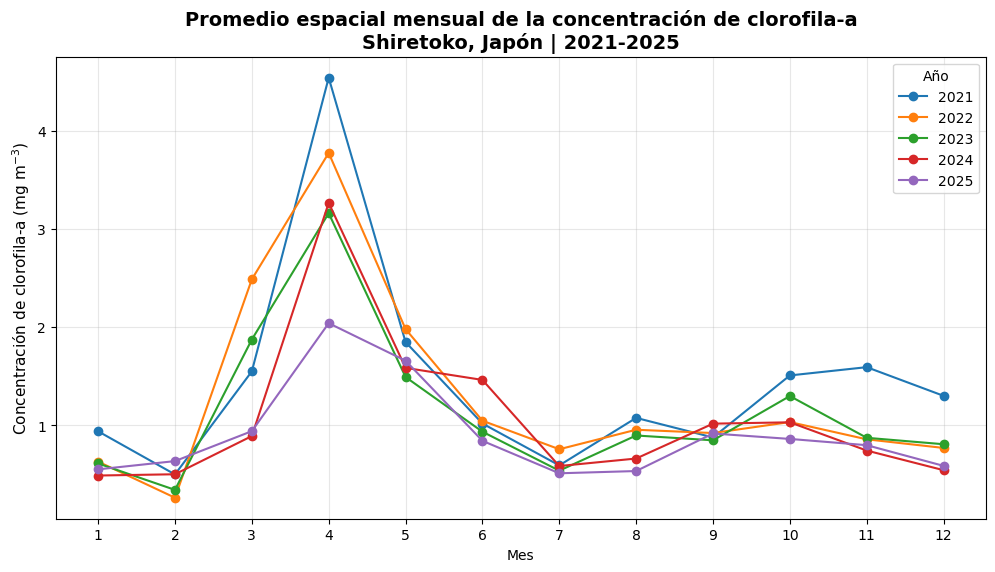

In [35]:
#Graficar la variación mensual

plt.figure(figsize=(12, 6))

for year in chl_mensual["year"].unique():

    datos = chl_mensual[
        chl_mensual["year"] == year
    ]

    plt.plot(
        datos["month"],
        datos["CHL"],
        marker="o",
        label=str(year)
    )

plt.title(
    "Promedio espacial mensual de la concentración de clorofila-a\n"
    "Shiretoko, Japón | 2021-2025",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Mes")
plt.ylabel(
    "Concentración de clorofila-a (mg m$^{-3}$)",
    fontsize=11
)
plt.xticks(range(1, 13))
plt.legend(title="Año")
plt.grid(alpha=0.3)

plt.show()

In [36]:
#Consulta de unidades de medición de clorofila
print(ds["CHL"].attrs)

{'ancillary_variables': 'flags CHL_uncertainty', 'coverage_content_type': 'modelResult', 'input_files_reprocessings': 'Processors versions: MODIS R2022.0.2NRT/VIIRSN R2022.0.3+R2022.0.3NRT/OLCIA 07.06+08.00/VIIRSJ1 R2022.0.2+R2022.0.2NRT/OLCIB 07.06+07.06NR+08.00/VIIRSJ2 R2025+R2025NRT', 'long_name': 'Chlorophyll-a concentration - Mean of the binned pixels', 'standard_name': 'mass_concentration_of_chlorophyll_a_in_sea_water', 'type': 'surface', 'units': 'milligram m-3', 'valid_max': np.float32(1000.0), 'valid_min': np.float32(0.0)}


In [37]:
# Organizar promedios mensuales por año
tabla_chl = chl_mensual.pivot(
    index="month",
    columns="year",
    values="CHL"
)

# Nombrar los meses
tabla_chl.index = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

# Mostrar tabla
print(tabla_chl.round(3))

year         2021   2022   2023   2024   2025
Enero       0.940  0.631  0.613  0.490  0.553
Febrero     0.501  0.264  0.344  0.503  0.637
Marzo       1.550  2.487  1.874  0.891  0.941
Abril       4.538  3.773  3.160  3.265  2.040
Mayo        1.848  1.980  1.492  1.585  1.658
Junio       1.019  1.048  0.936  1.463  0.843
Julio       0.593  0.757  0.539  0.586  0.513
Agosto      1.076  0.956  0.897  0.663  0.535
Septiembre  0.877  0.922  0.848  1.018  0.918
Octubre     1.508  1.034  1.299  1.031  0.862
Noviembre   1.593  0.858  0.874  0.744  0.799
Diciembre   1.301  0.771  0.808  0.544  0.588


Text(0.5, 36.72222222222221, 'Año')

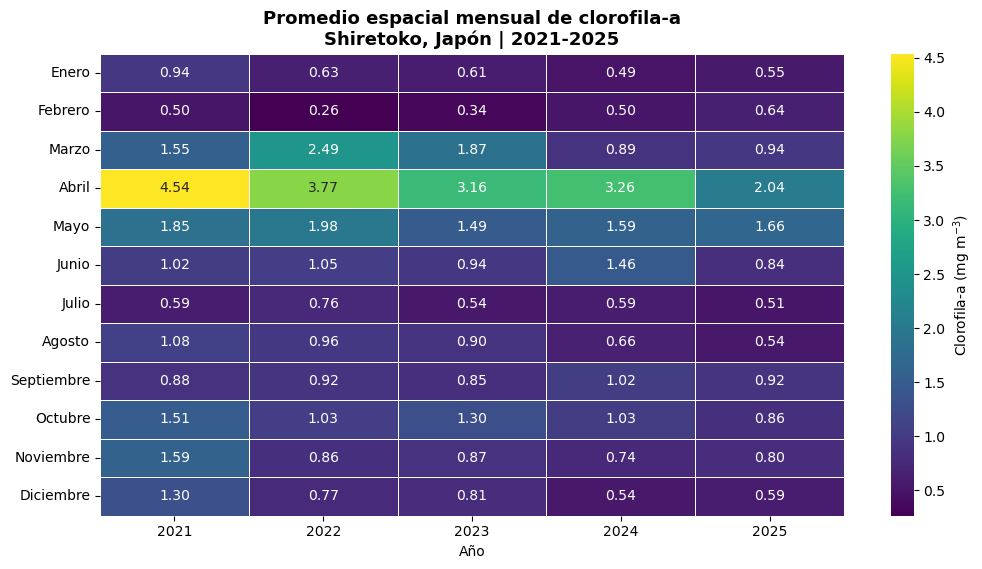

In [38]:
#Para identificar que meses y años presentan mayores y menores concentraciones de cloforila se genera un heat map

import seaborn as sns

plt.figure(figsize=(12, 6))

sns.heatmap(
    tabla_chl,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={
        "label": "Clorofila-a (mg m$^{-3}$)"
    }
)

plt.title(
    "Promedio espacial mensual de clorofila-a\n"
    "Shiretoko, Japón | 2021-2025",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Año")

In [39]:
#Unificación de análisis con horas acumuladas de esfuerzo aprente de pesca


In [40]:
#Se importa el csv de los datos ya procesados de GFW y se revisa su estructura
import pandas as pd

gfw_df = pd.read_csv("GFW_Shiretoko_2020_2024.csv")

print(gfw_df.head())
print(gfw_df.columns)
print(gfw_df.shape)

      date  detections  flag  gear_type      hours  vessel_ids  vessel_id  \
0  2020-09         NaN   NaN        NaN  20.724167           1        NaN   
1  2020-09         NaN   NaN        NaN   9.460278           1        NaN   
2  2020-07         NaN   NaN        NaN   0.970556           1        NaN   
3  2020-09         NaN   NaN        NaN   8.935278           1        NaN   
4  2020-04         NaN   NaN        NaN  52.052222           1        NaN   

   vessel_type  entry_timestamp  exit_timestamp  ...  last_transmission_date  \
0          NaN              NaN             NaN  ...                     NaN   
1          NaN              NaN             NaN  ...                     NaN   
2          NaN              NaN             NaN  ...                     NaN   
3          NaN              NaN             NaN  ...                     NaN   
4          NaN              NaN             NaN  ...                     NaN   

   imo  mmsi  call_sign  dataset                     rep

In [41]:
# Convertir la columna date a formato fecha
gfw_df["date"] = pd.to_datetime(
    gfw_df["date"],
    format="%Y-%m"
)

# Identificar los meses disponibles por año
meses_disponibles = (
    gfw_df.groupby(gfw_df["date"].dt.year)["date"]
    .apply(lambda x: sorted(x.dt.month.unique()))
)

display(meses_disponibles)

date
2020                     [4, 7, 9]
2021                           [4]
2022         [6, 7, 8, 10, 11, 12]
2023    [4, 5, 6, 7, 8, 9, 10, 12]
2024        [4, 5, 6, 7, 8, 9, 10]
Name: date, dtype: object

In [42]:
#Considerando los resultados del heat map, se propone hacer la comparación entre el mes de abril y el esfuerzo pesquero porque es en el que se presenta una mayor concentración promedio de clorofila.
#Sin embargo, no hay datos disponibles para 2022
# Filtrar abril
gfw_abril = gfw_df[
    gfw_df["date"].dt.month == 4
].copy()

# Resumen de horas por año
resumen_abril = (
    gfw_abril.groupby(gfw_abril["date"].dt.year)
    .agg(
        registros=("hours", "count"),
        horas_totales=("hours", "sum")
    )
)

display(resumen_abril)

,registros,horas_totales
date,,
2020,1,52.052222
2021,2,7.454444
2023,3,5.957500
2024,2,10.316389


In [43]:
# Seleccionar únicamente los años de interés
gfw_abril_comparacion = gfw_abril[
    gfw_abril["date"].dt.year.isin([2021, 2023, 2024])
].copy()

# Agrupar las horas por año y ubicación
gfw_mapa = (
    gfw_abril_comparacion
    .groupby(
        [
            gfw_abril_comparacion["date"].dt.year.rename("year"),
            "lat",
            "lon"
        ],
        as_index=False
    )
    .agg(
        horas=("hours", "sum"),
        registros=("hours", "count")
    )
)

display(gfw_mapa)

,year,lat,lon,horas,registros
0,2021,44.0,144.8,6.742500,1
1,2021,44.0,144.9,0.711944,1
2,2023,44.0,144.8,3.976667,1
3,2023,44.4,145.4,1.156667,1
4,2023,44.5,145.4,0.824167,1
5,2024,44.0,144.8,7.707778,1
6,2024,44.5,145.4,2.608611,1


In [44]:
# Seleccionar abril de 2021, 2023 y 2024
gfw_abril_comparacion = gfw_abril[
    gfw_abril["date"].dt.year.isin([2021, 2023, 2024])
].copy()

# Agrupar por año y ubicación
gfw_mapa = (
    gfw_abril_comparacion
    .groupby(
        [
            gfw_abril_comparacion["date"].dt.year.rename("year"),
            "lat",
            "lon"
        ],
        as_index=False
    )
    .agg(
        horas=("hours", "sum"),
        registros=("hours", "count")
    )
)

display(gfw_mapa)

,year,lat,lon,horas,registros
0,2021,44.0,144.8,6.742500,1
1,2021,44.0,144.9,0.711944,1
2,2023,44.0,144.8,3.976667,1
3,2023,44.4,145.4,1.156667,1
4,2023,44.5,145.4,0.824167,1
5,2024,44.0,144.8,7.707778,1
6,2024,44.5,145.4,2.608611,1


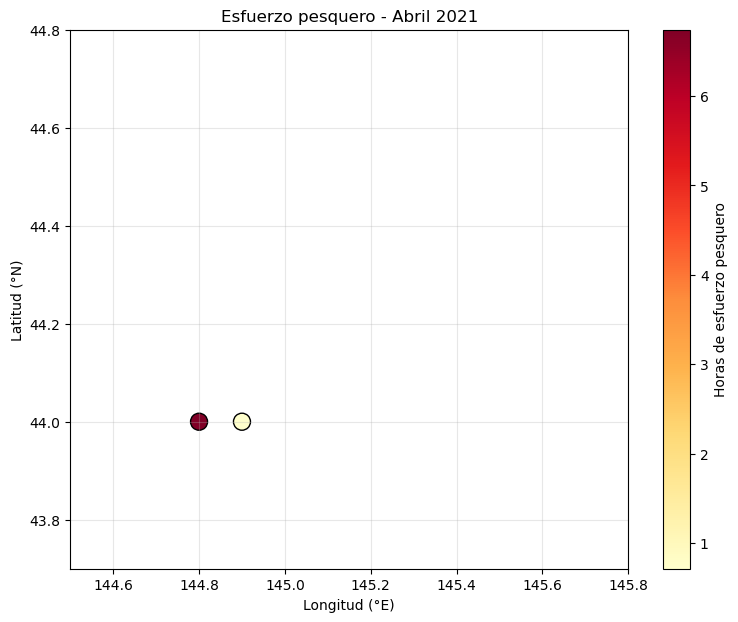

In [45]:
#Preparación de mapa para esfuerzo pesquero
import matplotlib.pyplot as plt

# Seleccionar abril de 2021
gfw_2021 = gfw_mapa[gfw_mapa["year"] == 2021]

# Crear mapa
plt.figure(figsize=(9, 7))

plt.scatter(
    gfw_2021["lon"],
    gfw_2021["lat"],
    c=gfw_2021["horas"],
    s=150,
    cmap="YlOrRd",
    edgecolor="black"
)

plt.colorbar(label="Horas de esfuerzo pesquero")

plt.xlabel("Longitud (°E)")
plt.ylabel("Latitud (°N)")
plt.title("Esfuerzo pesquero - Abril 2021")

plt.xlim(144.5, 145.8)
plt.ylim(43.7, 44.8)

plt.grid(alpha=0.3)
plt.show()

In [46]:
# Seleccionar clorofila-a de abril de 2021

chl_abril_2021 = chl_rect.sel(
    time="2021-04"
)

# Comprobar resultado
print(chl_abril_2021)

<xarray.DataArray 'CHL' (time: 1, latitude: 26, longitude: 31)> Size: 3kB
array([[[     nan,      nan, ..., 4.166763, 4.461305],
        [     nan,      nan, ..., 4.440126, 4.351635],
        ...,
        [4.810088, 4.407418, ..., 3.126201, 2.987892],
        [4.8856  , 4.889256, ..., 3.015061, 2.956921]]],
      shape=(1, 26, 31), dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 8B 2021-04-01
  * latitude     (latitude) float32 104B 43.73 43.77 43.81 ... 44.69 44.73 44.77
  * longitude    (longitude) float32 124B 144.5 144.6 144.6 ... 145.7 145.8
    spatial_ref  int64 8B 0
Attributes:
    ancillary_variables:        flags CHL_uncertainty
    coverage_content_type:      modelResult
    input_files_reprocessings:  Processors versions: MODIS R2022.0.2NRT/VIIRS...
    long_name:                  Chlorophyll-a concentration - Mean of the bin...
    standard_name:              mass_concentration_of_chlorophyll_a_in_sea_water
    type:                       surface
    uni

In [17]:
print(da)

NameError: name 'da' is not defined

In [47]:
print(gfw_mapa.head())

   year   lat    lon     horas  registros
0  2021  44.0  144.8  6.742500          1
1  2021  44.0  144.9  0.711944          1
2  2023  44.0  144.8  3.976667          1
3  2023  44.4  145.4  1.156667          1
4  2023  44.5  145.4  0.824167          1


In [52]:
import numpy as np

# Seleccionar los tres meses de abril
chl_2021 = chl_rect.sel(time="2021-04").values.flatten()
chl_2023 = chl_rect.sel(time="2023-04").values.flatten()
chl_2024 = chl_rect.sel(time="2024-04").values.flatten()

# Integrar los valores válidos
chl_todos = np.concatenate([
    chl_2021,
    chl_2023,
    chl_2024
])

chl_todos = chl_todos[~np.isnan(chl_todos)]

# Estadísticos descriptivos
print("Mínimo:", np.min(chl_todos))
print("Máximo:", np.max(chl_todos))
print("Percentil 2:", np.percentile(chl_todos, 2))
print("Percentil 5:", np.percentile(chl_todos, 5))
print("Mediana:", np.median(chl_todos))
print("Percentil 95:", np.percentile(chl_todos, 95))
print("Percentil 98:", np.percentile(chl_todos, 98))

Mínimo: 0.89127123
Máximo: 12.573718
Percentil 2: 1.8120139
Percentil 5: 2.14065
Mediana: 3.4765449
Percentil 95: 6.1098185
Percentil 98: 7.1301556


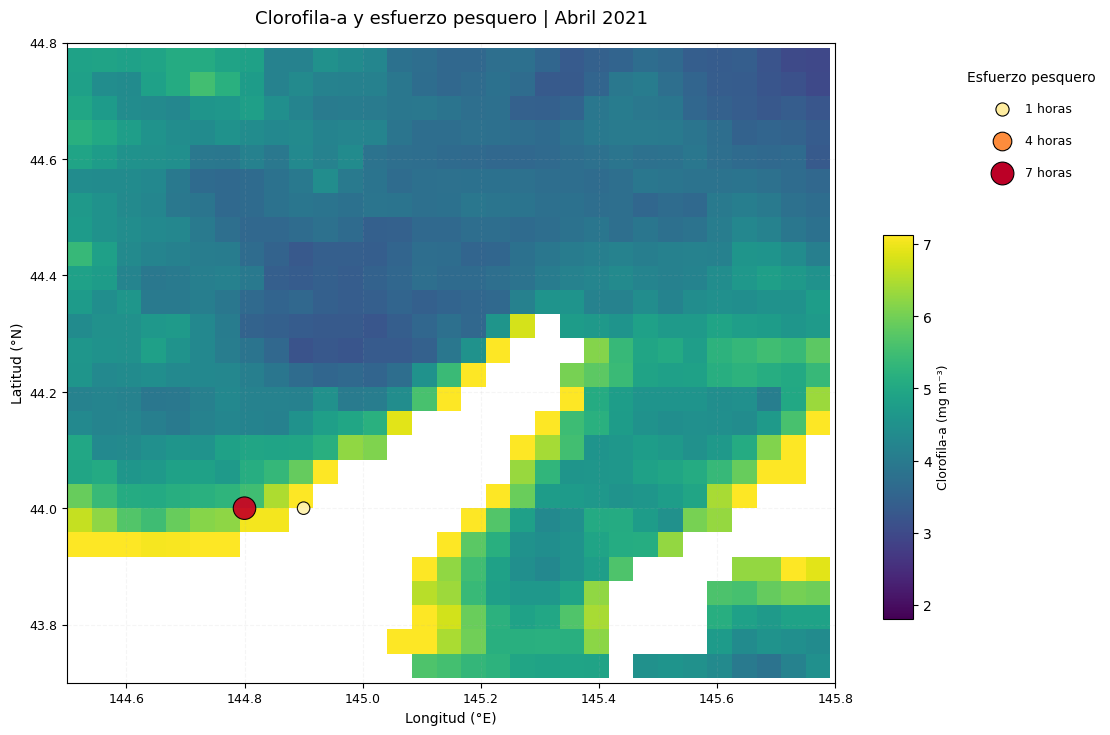

In [63]:
import matplotlib.pyplot as plt

# ==========================================
# MAPA INTEGRADO: ABRIL 2021
# ==========================================

# 1. Seleccionar datos
gfw_2021 = gfw_mapa[
    gfw_mapa["year"] == 2021
].copy()

chl_abril_2021 = chl_rect.sel(time="2021-04")

# 2. Crear figura
fig, ax = plt.subplots(figsize=(12, 8))

# Reservar espacio para referencias
fig.subplots_adjust(
    left=0.10,
    right=0.74,
    top=0.90,
    bottom=0.10
)

# 3. Raster de clorofila-a
im = ax.pcolormesh(
    chl_abril_2021["longitude"],
    chl_abril_2021["latitude"],
    chl_abril_2021.squeeze(),
    cmap="viridis",
    vmin=1.81,
    vmax=7.13,
    shading="auto",
    rasterized=True
)

# 4. Definir escala de color de pesca
norm = plt.Normalize(vmin=0, vmax=8)
cmap_pesca = plt.cm.YlOrRd

# 5. Tamaño y color de los puntos
tamanos = 60 + gfw_2021["horas"] * 30
colores = cmap_pesca(norm(gfw_2021["horas"]))

ax.scatter(
    gfw_2021["lon"],
    gfw_2021["lat"],
    s=tamanos,
    c=colores,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.95,
    zorder=3
)

# 6. Barra de color de clorofila-a
cax = fig.add_axes([0.78, 0.18, 0.025, 0.48])

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(
    "Clorofila-a (mg m⁻³)",
    fontsize=9
)

# 7. Leyenda de tamaño y color de pesca
for horas in [1, 4, 7]:
    ax.scatter(
        [],
        [],
        s=60 + horas * 30,
        color=cmap_pesca(norm(horas)),
        edgecolor="black",
        linewidth=0.8,
        label=f"{horas} horas"
    )

fig.legend(
    title="Esfuerzo pesquero",
    loc="upper left",
    bbox_to_anchor=(0.84, 0.88),
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    labelspacing=1.5
)

# 8. Extensión geográfica
ax.set_xlim(144.5, 145.8)
ax.set_ylim(43.7, 44.8)

# 9. Etiquetas y título
ax.set_xlabel("Longitud (°E)", fontsize=10)
ax.set_ylabel("Latitud (°N)", fontsize=10)

ax.set_title(
    "Clorofila-a y esfuerzo pesquero | Abril 2021",
    fontsize=13,
    pad=14
)

ax.tick_params(labelsize=9)
ax.grid(alpha=0.12, linestyle="--")

# 10. Mostrar
plt.show()

In [56]:
# Seleccionar clorofila-a de abril de 2023

chl_abril_2023 = chl_rect.sel(
    time="2023-04"
)

print(chl_abril_2023)

<xarray.DataArray 'CHL' (time: 1, latitude: 26, longitude: 31)> Size: 3kB
array([[[     nan,      nan, ..., 5.232389, 5.365454],
        [     nan,      nan, ..., 6.048241, 5.768631],
        ...,
        [2.864218, 2.812221, ..., 2.138891, 2.226336],
        [2.851206, 2.857538, ..., 2.114195, 2.068918]]],
      shape=(1, 26, 31), dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 8B 2023-04-01
  * latitude     (latitude) float32 104B 43.73 43.77 43.81 ... 44.69 44.73 44.77
  * longitude    (longitude) float32 124B 144.5 144.6 144.6 ... 145.7 145.8
    spatial_ref  int64 8B 0
Attributes:
    ancillary_variables:        flags CHL_uncertainty
    coverage_content_type:      modelResult
    input_files_reprocessings:  Processors versions: MODIS R2022.0.2NRT/VIIRS...
    long_name:                  Chlorophyll-a concentration - Mean of the bin...
    standard_name:              mass_concentration_of_chlorophyll_a_in_sea_water
    type:                       surface
    uni

In [57]:
gfw_2023 = gfw_mapa[
    gfw_mapa["year"] == 2023
].copy()

print(gfw_2023)

   year   lat    lon     horas  registros
2  2023  44.0  144.8  3.976667          1
3  2023  44.4  145.4  1.156667          1
4  2023  44.5  145.4  0.824167          1


Abril 2021: 4.54 mg m-3
Abril 2023: 3.16 mg m-3
Abril 2024: 3.26 mg m-3


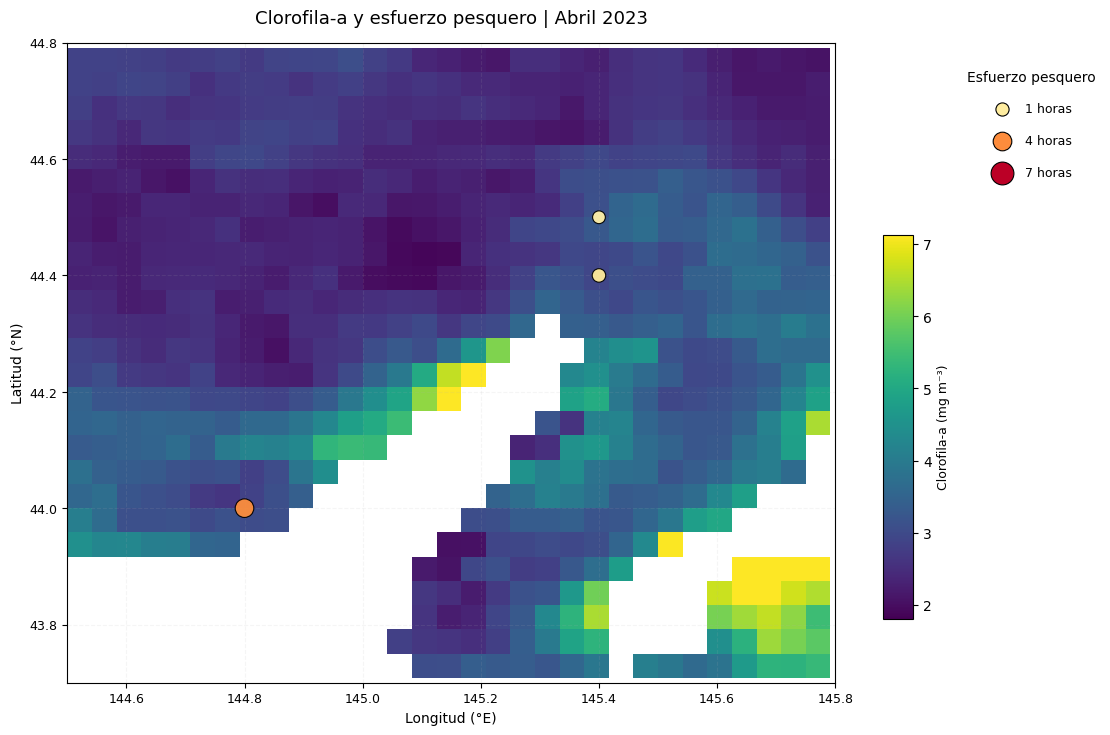

In [62]:
import matplotlib.pyplot as plt

# ==========================================
# MAPA INTEGRADO: ABRIL 2023
# ==========================================

# 1. Seleccionar datos
gfw_2023 = gfw_mapa[
    gfw_mapa["year"] == 2023
].copy()

chl_abril_2023 = chl_rect.sel(time="2023-04")

# 2. Crear figura
fig, ax = plt.subplots(figsize=(12, 8))

# Reservar espacio para referencias
fig.subplots_adjust(
    left=0.10,
    right=0.74,
    top=0.90,
    bottom=0.10
)

# 3. Raster de clorofila-a
im = ax.pcolormesh(
    chl_abril_2023["longitude"],
    chl_abril_2023["latitude"],
    chl_abril_2023.squeeze(),
    cmap="viridis",
    vmin=1.81,
    vmax=7.13,
    shading="auto",
    rasterized=True
)

# 4. Definir escala de color de pesca
norm = plt.Normalize(vmin=0, vmax=8)
cmap_pesca = plt.cm.YlOrRd

# 5. Tamaño y color de los puntos
tamanos = 60 + gfw_2023["horas"] * 30
colores = cmap_pesca(norm(gfw_2023["horas"]))

ax.scatter(
    gfw_2023["lon"],
    gfw_2023["lat"],
    s=tamanos,
    c=colores,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.95,
    zorder=3
)

# 6. Barra de color de clorofila-a
cax = fig.add_axes([0.78, 0.18, 0.025, 0.48])

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(
    "Clorofila-a (mg m⁻³)",
    fontsize=9
)

# 7. Leyenda de tamaño y color de pesca
for horas in [1, 4, 7]:
    ax.scatter(
        [],
        [],
        s=60 + horas * 30,
        color=cmap_pesca(norm(horas)),
        edgecolor="black",
        linewidth=0.8,
        label=f"{horas} horas"
    )

fig.legend(
    title="Esfuerzo pesquero",
    loc="upper left",
    bbox_to_anchor=(0.84, 0.88),
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    labelspacing=1.5
)

# 8. Extensión geográfica
ax.set_xlim(144.5, 145.8)
ax.set_ylim(43.7, 44.8)

# 9. Etiquetas y título
ax.set_xlabel("Longitud (°E)", fontsize=10)
ax.set_ylabel("Latitud (°N)", fontsize=10)

ax.set_title(
    "Clorofila-a y esfuerzo pesquero | Abril 2023",
    fontsize=13,
    pad=14
)

ax.tick_params(labelsize=9)
ax.grid(alpha=0.12, linestyle="--")

# 10. Mostrar
plt.show()

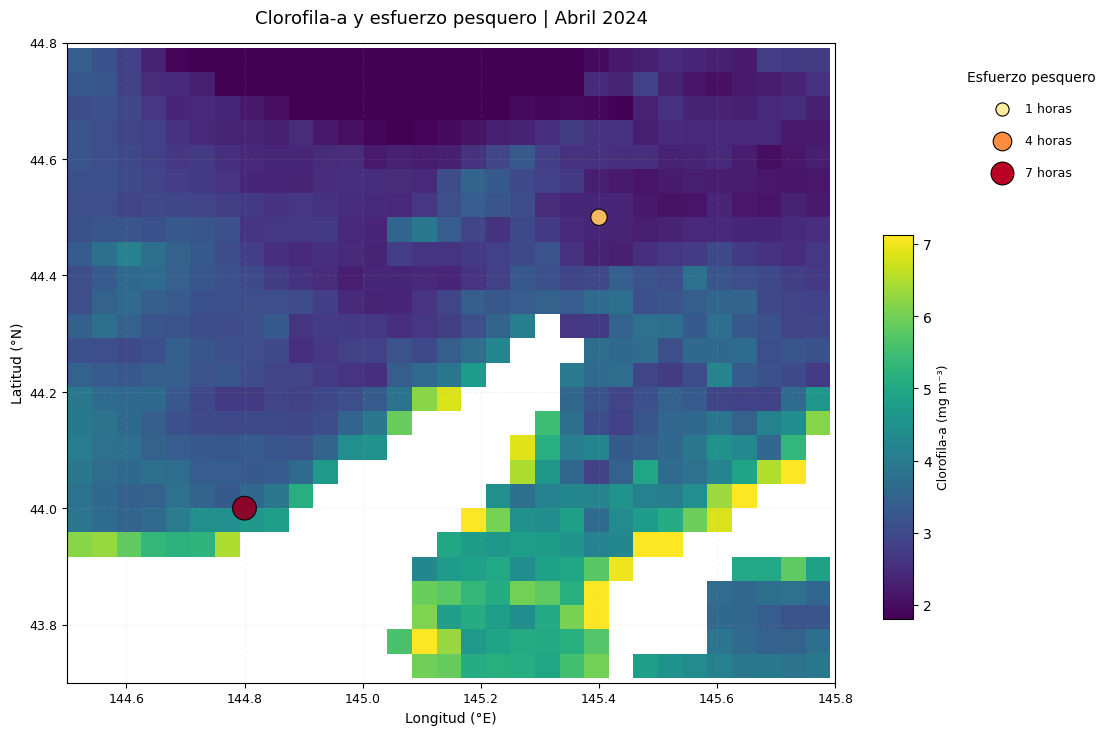

In [64]:
import matplotlib.pyplot as plt

# ==========================================
# MAPA INTEGRADO: ABRIL 2024
# ==========================================

# 1. Seleccionar datos
gfw_2024 = gfw_mapa[
    gfw_mapa["year"] == 2024
].copy()

chl_abril_2024 = chl_rect.sel(time="2024-04")

# 2. Crear figura
fig, ax = plt.subplots(figsize=(12, 8))

# Reservar espacio para referencias
fig.subplots_adjust(
    left=0.10,
    right=0.74,
    top=0.90,
    bottom=0.10
)

# 3. Raster de clorofila-a
im = ax.pcolormesh(
    chl_abril_2024["longitude"],
    chl_abril_2024["latitude"],
    chl_abril_2024.squeeze(),
    cmap="viridis",
    vmin=1.81,
    vmax=7.13,
    shading="auto",
    rasterized=True
)

# 4. Definir escala de color de pesca
norm = plt.Normalize(vmin=0, vmax=8)
cmap_pesca = plt.cm.YlOrRd

# 5. Tamaño y color de los puntos
tamanos = 60 + gfw_2024["horas"] * 30
colores = cmap_pesca(norm(gfw_2024["horas"]))

ax.scatter(
    gfw_2024["lon"],
    gfw_2024["lat"],
    s=tamanos,
    c=colores,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.95,
    zorder=3
)

# 6. Barra de color de clorofila-a
cax = fig.add_axes([0.78, 0.18, 0.025, 0.48])

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(
    "Clorofila-a (mg m⁻³)",
    fontsize=9
)

# 7. Leyenda de tamaño y color de pesca
for horas in [1, 4, 7]:
    ax.scatter(
        [],
        [],
        s=60 + horas * 30,
        color=cmap_pesca(norm(horas)),
        edgecolor="black",
        linewidth=0.8,
        label=f"{horas} horas"
    )

fig.legend(
    title="Esfuerzo pesquero",
    loc="upper left",
    bbox_to_anchor=(0.84, 0.88),
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    labelspacing=1.5
)

# 8. Extensión geográfica
ax.set_xlim(144.5, 145.8)
ax.set_ylim(43.7, 44.8)

# 9. Etiquetas y título
ax.set_xlabel("Longitud (°E)", fontsize=10)
ax.set_ylabel("Latitud (°N)", fontsize=10)

ax.set_title(
    "Clorofila-a y esfuerzo pesquero | Abril 2024",
    fontsize=13,
    pad=14
)

ax.tick_params(labelsize=9)
ax.grid(alpha=0.12, linestyle="--")

# 10. Mostrar
plt.show()

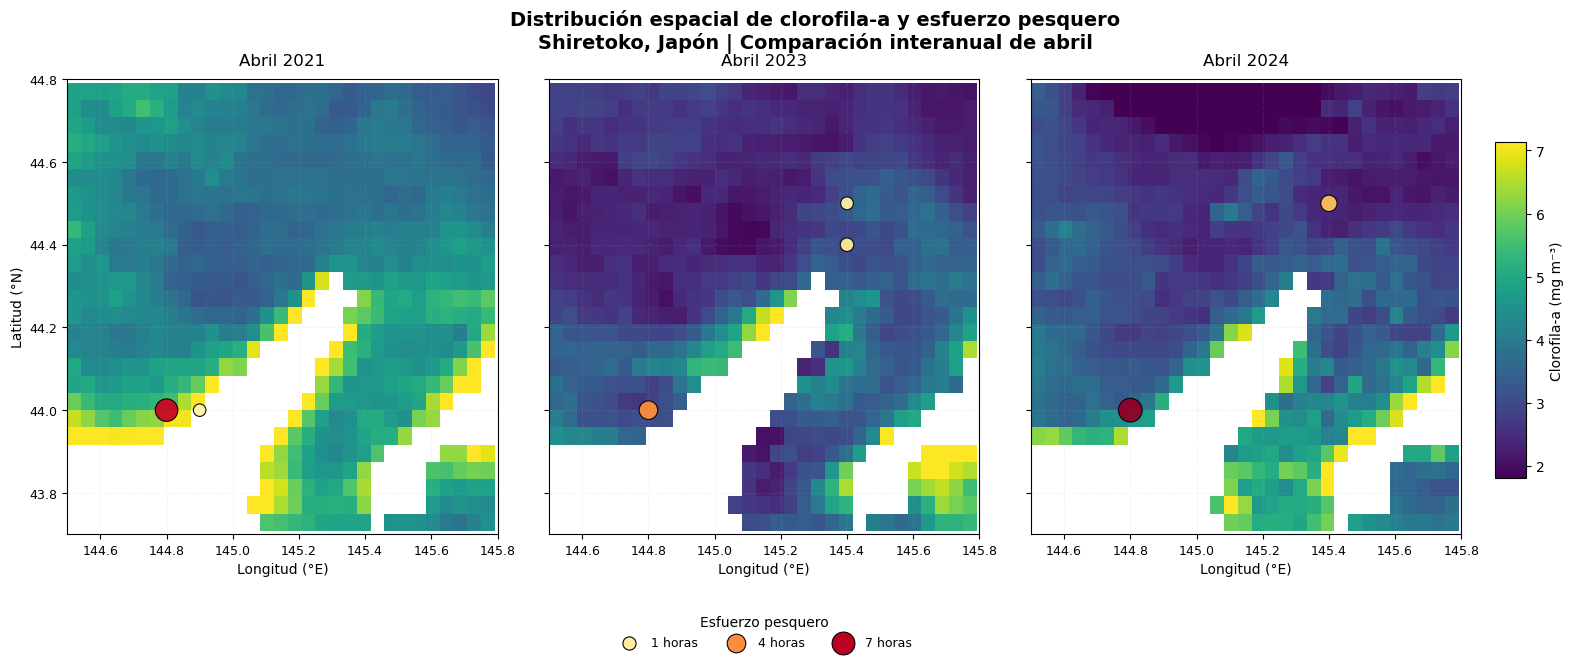

In [65]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# ==========================================
# FIGURA COMPARATIVA: ABRIL 2021, 2023 Y 2024
# ==========================================

# 1. Configuración de años y escalas
anios = [2021, 2023, 2024]

vmin_chl = 1.81
vmax_chl = 7.13

norm_pesca = Normalize(vmin=0, vmax=8)
cmap_pesca = plt.cm.YlOrRd

# 2. Crear figura con tres paneles
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 7),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.87,
    bottom=0.22,
    wspace=0.12
)

# 3. Diccionario de rasters de clorofila
chl_datos = {
    2021: chl_rect.sel(time="2021-04").squeeze(),
    2023: chl_rect.sel(time="2023-04").squeeze(),
    2024: chl_rect.sel(time="2024-04").squeeze()
}

# 4. Generar cada mapa
for ax, anio in zip(axes, anios):

    # Seleccionar raster de clorofila
    chl_mes = chl_datos[anio]

    # Seleccionar esfuerzo pesquero
    gfw_anio = gfw_mapa[
        gfw_mapa["year"] == anio
    ].copy()

    # Raster de clorofila-a
    im = ax.pcolormesh(
        chl_mes["longitude"],
        chl_mes["latitude"],
        chl_mes.values,
        cmap="viridis",
        vmin=vmin_chl,
        vmax=vmax_chl,
        shading="auto",
        rasterized=True
    )

    # Tamaño y color de los puntos
    tamanos = 60 + gfw_anio["horas"] * 30

    colores = cmap_pesca(
        norm_pesca(gfw_anio["horas"])
    )

    ax.scatter(
        gfw_anio["lon"],
        gfw_anio["lat"],
        s=tamanos,
        c=colores,
        edgecolor="black",
        linewidth=0.8,
        alpha=0.95,
        zorder=3
    )

    # Extensión geográfica
    ax.set_xlim(144.5, 145.8)
    ax.set_ylim(43.7, 44.8)

    # Etiquetas
    ax.set_xlabel("Longitud (°E)", fontsize=10)
    ax.set_title(f"Abril {anio}", fontsize=12, pad=10)

    ax.tick_params(labelsize=9)
    ax.grid(alpha=0.12, linestyle="--")

# Etiqueta del eje Y
axes[0].set_ylabel("Latitud (°N)", fontsize=10)

# 5. Barra de color común de clorofila-a
cax = fig.add_axes([0.90, 0.30, 0.018, 0.48])

cbar = fig.colorbar(im, cax=cax)

cbar.set_label(
    "Clorofila-a (mg m⁻³)",
    fontsize=10
)

# 6. Leyenda común de esfuerzo pesquero
for horas in [1, 4, 7]:
    axes[0].scatter(
        [],
        [],
        s=60 + horas * 30,
        color=cmap_pesca(norm_pesca(horas)),
        edgecolor="black",
        linewidth=0.8,
        label=f"{horas} horas"
    )

fig.legend(
    title="Esfuerzo pesquero",
    loc="lower center",
    bbox_to_anchor=(0.47, 0.04),
    ncol=3,
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

# 7. Título general
fig.suptitle(
    "Distribución espacial de clorofila-a y esfuerzo pesquero\n"
    "Shiretoko, Japón | Comparación interanual de abril",
    fontsize=14,
    fontweight="bold",
    y=0.97
)

plt.show()

In [68]:
#Pasemos al análisis de la serie temporal de clorofila y esfuerzo pesquero

# Preparar datos de esfuerzo pesquero

gfw_df["date"] = pd.to_datetime(gfw_df["date"])

gfw_df["year"] = gfw_df["date"].dt.year
gfw_df["month"] = gfw_df["date"].dt.month

# Filtrar periodo de coincidencia: 2021-2024
gfw_periodo = gfw_df[
    gfw_df["year"].between(2021, 2024)
].copy()

# Agregar horas por mes
gfw_mensual = (
    gfw_periodo
    .groupby(["year", "month"], as_index=False)
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count")
    )
)

display(gfw_mensual)

,year,month,horas_totales,registros
0,2021,4,7.454444,2
1,2022,6,4.805169,1
2,2022,7,2.333056,2
3,2022,8,0.493889,1
4,2022,10,6.009167,2
5,2022,11,2.667222,2
6,2022,12,12.877500,3
7,2023,4,5.957500,3
8,2023,5,4.968889,1
9,2023,6,34.174722,4


In [72]:
# Convertir nombres de meses a números
meses = {
    "Enero": 1,
    "Febrero": 2,
    "Marzo": 3,
    "Abril": 4,
    "Mayo": 5,
    "Junio": 6,
    "Julio": 7,
    "Agosto": 8,
    "Septiembre": 9,
    "Octubre": 10,
    "Noviembre": 11,
    "Diciembre": 12
}

chl_largo["month"] = chl_largo["month"].map(meses)

print(chl_largo.head())
print(chl_largo.dtypes)

   month  year  clorofila
0      1  2021   0.939793
1      1  2022   0.631457
2      1  2023   0.612603
3      1  2024   0.489804
4      1  2025   0.552666
month          int64
year           int64
clorofila    float32
dtype: object


In [73]:
# Integrar clorofila-a
datos_integrados = calendario.merge(
    chl_largo,
    on=["year", "month"],
    how="left"
)

# Integrar esfuerzo pesquero
datos_integrados = datos_integrados.merge(
    gfw_mensual,
    on=["year", "month"],
    how="left"
)

# Crear fecha
datos_integrados["fecha"] = pd.to_datetime(
    dict(
        year=datos_integrados["year"],
        month=datos_integrados["month"],
        day=1
    )
)

# Ordenar cronológicamente
datos_integrados = datos_integrados.sort_values("fecha")

display(datos_integrados)

,year,month,clorofila,horas_totales,registros,fecha
0,2021,1,0.939793,NaN,NaN,2021-01-01
1,2021,2,0.500978,NaN,NaN,2021-02-01
2,2021,3,1.549929,NaN,NaN,2021-03-01
3,2021,4,4.538437,7.454444,2.0,2021-04-01
4,2021,5,1.848213,NaN,NaN,2021-05-01
5,2021,6,1.019190,NaN,NaN,2021-06-01
6,2021,7,0.592907,NaN,NaN,2021-07-01
7,2021,8,1.076465,NaN,NaN,2021-08-01
8,2021,9,0.877336,NaN,NaN,2021-09-01
9,2021,10,1.508437,NaN,NaN,2021-10-01


In [74]:
#Comprobar el resultado
print("Número de registros:", len(datos_integrados))
print("\nDatos faltantes:")
print(datos_integrados[["clorofila", "horas_totales"]].isna().sum())

Número de registros: 48

Datos faltantes:
clorofila         0
horas_totales    26
dtype: int64


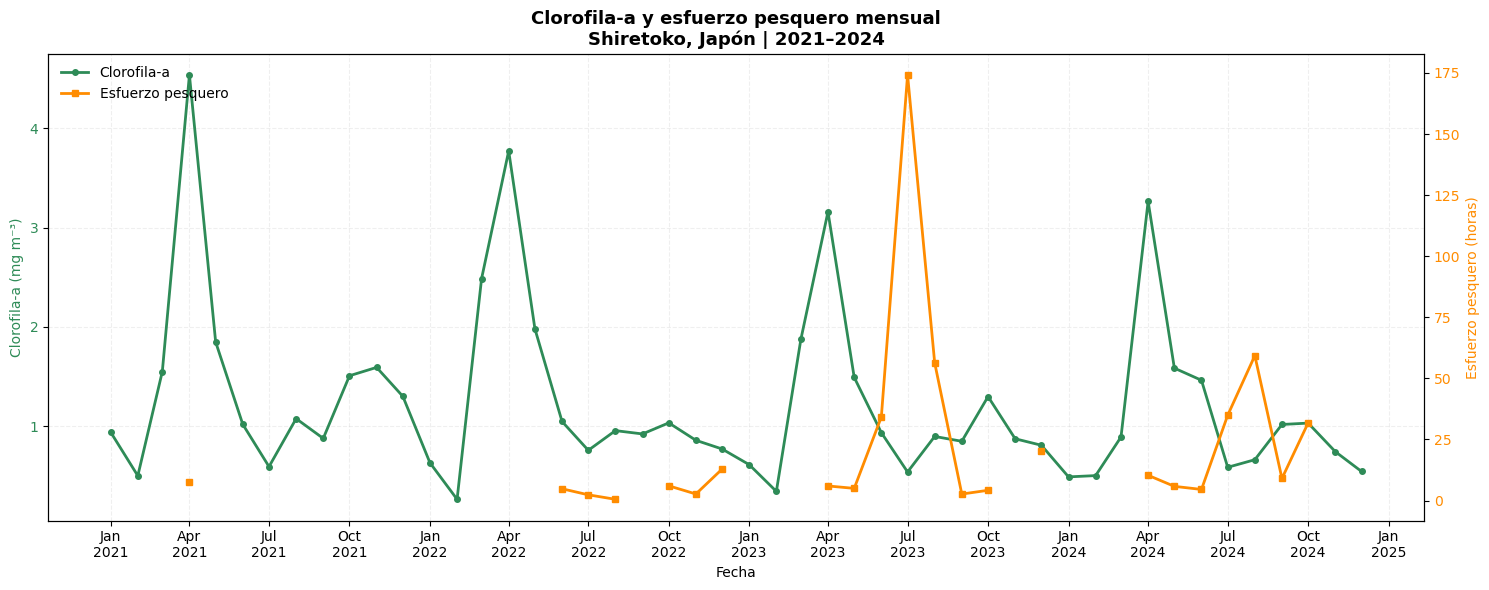

In [75]:
#Serie temporal integrada
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Crear figura
fig, ax1 = plt.subplots(figsize=(15, 6))

# Eje 1: clorofila-a
ax1.plot(
    datos_integrados["fecha"],
    datos_integrados["clorofila"],
    color="seagreen",
    linewidth=2,
    marker="o",
    markersize=4,
    label="Clorofila-a"
)

ax1.set_xlabel("Fecha")
ax1.set_ylabel(
    "Clorofila-a (mg m⁻³)",
    color="seagreen"
)
ax1.tick_params(axis="y", labelcolor="seagreen")

# Eje 2: esfuerzo pesquero
ax2 = ax1.twinx()

ax2.plot(
    datos_integrados["fecha"],
    datos_integrados["horas_totales"],
    color="darkorange",
    linewidth=2,
    marker="s",
    markersize=5,
    label="Esfuerzo pesquero"
)

ax2.set_ylabel(
    "Esfuerzo pesquero (horas)",
    color="darkorange"
)
ax2.tick_params(axis="y", labelcolor="darkorange")

# Formato del eje temporal
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

# Título
plt.title(
    "Clorofila-a y esfuerzo pesquero mensual\n"
    "Shiretoko, Japón | 2021–2024",
    fontsize=13,
    fontweight="bold"
)

# Leyenda conjunta
lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()

ax1.legend(
    lineas1 + lineas2,
    etiquetas1 + etiquetas2,
    loc="upper left",
    frameon=False
)

ax1.grid(alpha=0.2, linestyle="--")

plt.tight_layout()
plt.show()


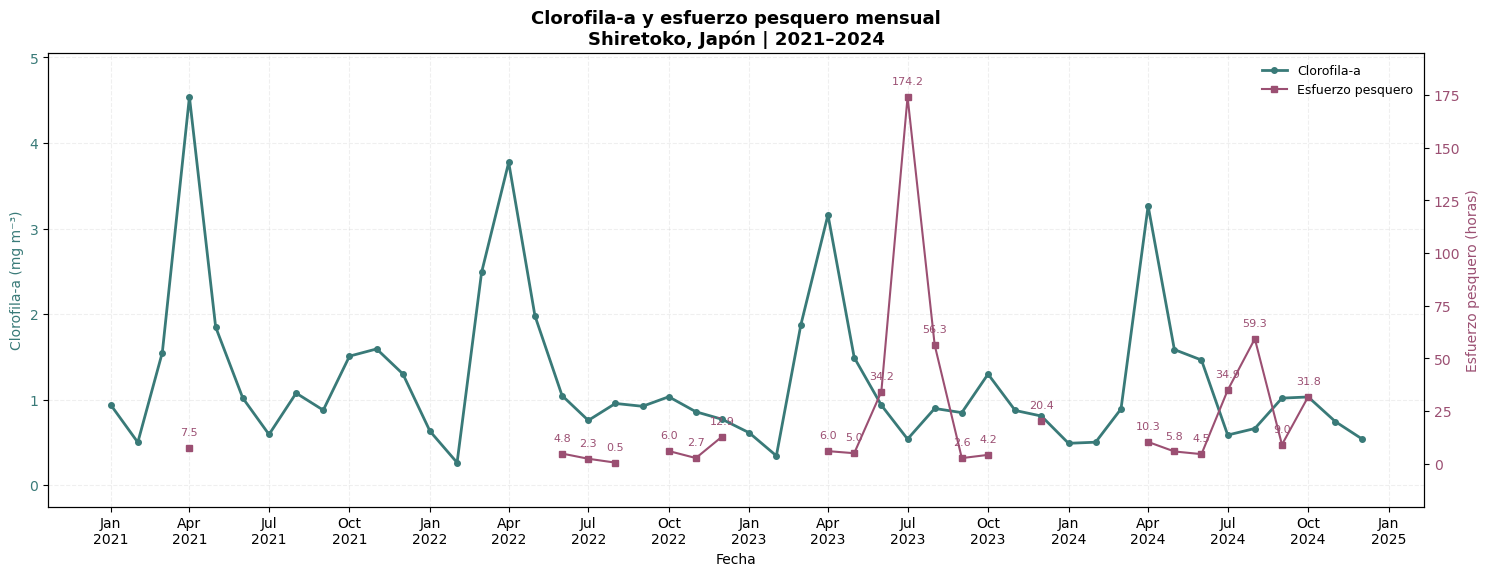

In [80]:
# ==========================================
# SERIE TEMPORAL INTEGRADA
# CLOROFILA-A Y ESFUERZO PESQUERO
# SHIRETOKO, JAPÓN | 2021-2024
# ==========================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Definir colores
color_chl = "#397A78"   # Azul petróleo
color_gfw = "#9B4F72"   # Vino

# Crear figura
fig, ax1 = plt.subplots(figsize=(15, 6))

# ==========================================
# 1. CLOROFILA-A
# ==========================================

ax1.plot(
    datos_integrados["fecha"],
    datos_integrados["clorofila"],
    color=color_chl,
    linewidth=2,
    marker="o",
    markersize=4,
    label="Clorofila-a"
)

ax1.set_xlabel("Fecha", fontsize=10)

ax1.set_ylabel(
    "Clorofila-a (mg m⁻³)",
    color=color_chl,
    fontsize=10
)

ax1.tick_params(
    axis="y",
    labelcolor=color_chl
)

# Aumentar margen vertical
ax1.margins(y=0.12)

# ==========================================
# 2. ESFUERZO PESQUERO
# ==========================================

ax2 = ax1.twinx()

ax2.plot(
    datos_integrados["fecha"],
    datos_integrados["horas_totales"],
    color=color_gfw,
    linewidth=1.5,
    marker="s",
    markersize=5,
    label="Esfuerzo pesquero"
)

ax2.set_ylabel(
    "Esfuerzo pesquero (horas)",
    color=color_gfw,
    fontsize=10
)

ax2.tick_params(
    axis="y",
    labelcolor=color_gfw
)

# Aumentar margen vertical
ax2.margins(y=0.12)

# ==========================================
# 3. ETIQUETAS DE HORAS EN CADA PUNTO
# ==========================================

for fecha, horas in zip(
    datos_integrados["fecha"],
    datos_integrados["horas_totales"]
):

    if pd.notna(horas):

        ax2.annotate(
            f"{horas:.1f}",
            (fecha, horas),
            textcoords="offset points",
            xytext=(0, 9),
            ha="center",
            fontsize=8,
            color=color_gfw
        )

# ==========================================
# 4. FORMATO DEL EJE TEMPORAL
# ==========================================

ax1.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y")
)

# ==========================================
# 5. TÍTULO
# ==========================================

plt.title(
    "Clorofila-a y esfuerzo pesquero mensual\n"
    "Shiretoko, Japón | 2021–2024",
    fontsize=13,
    fontweight="bold"
)

# ==========================================
# 6. LEYENDA SUPERIOR DERECHA
# ==========================================

lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()

ax1.legend(
    lineas1 + lineas2,
    etiquetas1 + etiquetas2,
    loc="upper right",
    frameon=False,
    fontsize=9
)

# ==========================================
# 7. ESTÉTICA FINAL
# ==========================================

ax1.grid(
    alpha=0.2,
    linestyle="--"
)

plt.tight_layout()

# Ajustar margen superior de la figura
plt.subplots_adjust(top=0.88)

plt.show()